In [49]:
# Загрузка, обработка таблиц и подготовка выборок данных
import pandas as pd

# Визуализация данных, построение графиков распределений и боксплотов
import seaborn as sns

# Модуль базовых статистических тестов библиотеки SciPy
from scipy import stats

# Построение линейной модели для ANOVA (дисперсионного анализа)
from statsmodels.formula.api import ols

# Расчет таблицы дисперсионного анализа (ANOVA) по построенной модели
from statsmodels.stats.anova import anova_lm

# Инструменты statsmodels (для построения графиков квантилей QQ-plot)
import statsmodels.api as sm

# Проведение критерия Тьюки (Post-hoc анализ для попарных сравнений)
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# Функции для корреляционного анализа (коэффициенты Пирсона, Спирмена, Кендалла)
from scipy.stats import pearsonr, spearmanr, kendalltau



In [50]:
# Импортируем matplotlib для настройки параметров осей
import matplotlib.pyplot as plt

# Настраиваем минималистичный стиль и крупный читаемый шрифт
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.1)

# Задаем свою стильную палитру (Глубокий синий, Серый, Коралловый акцент)
my_palette = ["#1a365d", "#718096", "#e53e3e"]
sns.set_palette(my_palette)

# Убираем рамки графика сверху и справа для чистоты отображения
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

1. **Факторы зарплат:** Что сильнее всего влияет на зарплатную вилку вакансий в сфере Data Science?
2. **Распределение грейдов:** Как распределены позиции (грейды) сотрудников в компаниях разного размера? Какие выводы можно сделать на основе этого распределения?
3. **Выбор компании:** В компанию какого размера выгоднее устраиваться кандидатам уровней *Middle* и *Senior*?

In [51]:
data = pd.read_csv("datas/ds_salaries.csv", index_col=0)
data.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,company_location,company_size
0,2020,MI,FT,Data Scientist,70000,EUR,79833,DE,DE,L
1,2020,SE,FT,Machine Learning Scientist,260000,USD,260000,JP,JP,S
2,2020,SE,FT,Big Data Engineer,85000,GBP,109024,GB,GB,M
3,2020,MI,FT,Product Data Analyst,20000,USD,20000,HN,HN,S
4,2020,SE,FT,Machine Learning Engineer,150000,USD,150000,US,US,L


In [52]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 607 entries, 0 to 606
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   work_year           607 non-null    int64
 1   experience_level    607 non-null    str  
 2   employment_type     607 non-null    str  
 3   job_title           607 non-null    str  
 4   salary              607 non-null    int64
 5   salary_currency     607 non-null    str  
 6   salary_in_usd       607 non-null    int64
 7   employee_residence  607 non-null    str  
 8   company_location    607 non-null    str  
 9   company_size        607 non-null    str  
dtypes: int64(3), str(7)
memory usage: 47.5 KB


In [53]:
data.work_year.unique() # дискретные 

array([2020, 2021, 2022])

In [54]:
data.experience_level.unique() # порядковые

<StringArray>
['MI', 'SE', 'JN', 'TL']
Length: 4, dtype: str

In [55]:
data.company_size.unique() # порядковые

<StringArray>
['L', 'S', 'M']
Length: 3, dtype: str

In [56]:
data.job_title.unique() # категориальные

<StringArray>
[                          'Data Scientist',
               'Machine Learning Scientist',
                        'Big Data Engineer',
                     'Product Data Analyst',
                'Machine Learning Engineer',
                             'Data Analyst',
                      'Lead Data Scientist',
                    'Business Data Analyst',
                       'Lead Data Engineer',
                        'Lead Data Analyst',
                            'Data Engineer',
                  'Data Science Consultant',
                          'BI Data Analyst',
                 'Director of Data Science',
                       'Research Scientist',
                 'Machine Learning Manager',
                 'Data Engineering Manager',
 'Machine Learning Infrastructure Engineer',
                              'ML Engineer',
                             'AI Scientist',
                 'Computer Vision Engineer',
                 'Principal Data Scientis

In [57]:
data.salary_currency.unique() # категориальные

<StringArray>
['EUR', 'USD', 'GBP', 'HUF', 'INR', 'JPY', 'CNY', 'MXN', 'CAD', 'DKK', 'PLN',
 'SGD', 'CLP', 'BRL', 'TRY', 'AUD', 'CHF']
Length: 17, dtype: str

1. **Факторы зарплат:** Что сильнее всего влияет на зарплатную вилку вакансий в сфере Data Science?

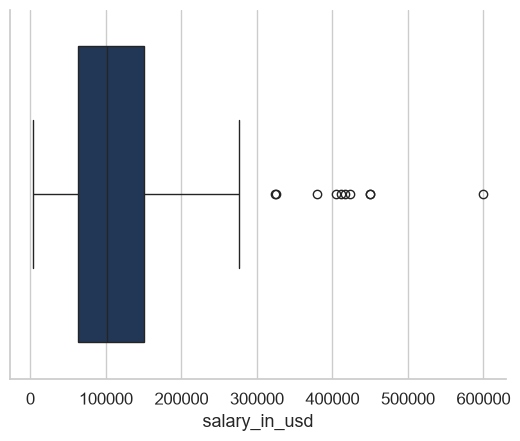

In [58]:
sns.boxplot(data=data,x="salary_in_usd");
plt.savefig('images/salary_chart1.png', dpi=300, bbox_inches='tight')
plt.show()

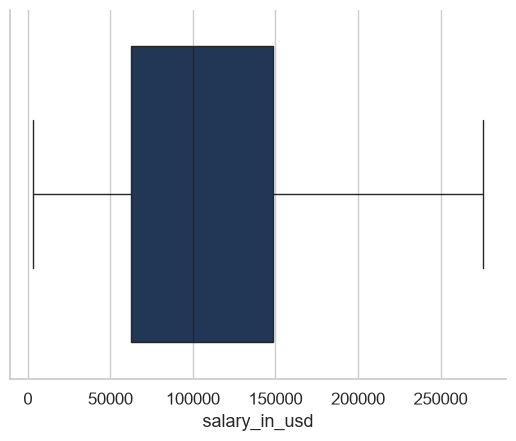

In [59]:
data = data[data.salary_in_usd < 300_000]
sns.boxplot(data=data,x="salary_in_usd");
plt.savefig('images/salary_chart2.png', dpi=300, bbox_inches='tight')
plt.show()

In [60]:
spearmanr(data.salary_in_usd, data.experience_level) # p-value < 0.05 

SignificanceResult(statistic=np.float64(0.5579476468827914), pvalue=np.float64(3.795022662679301e-50))

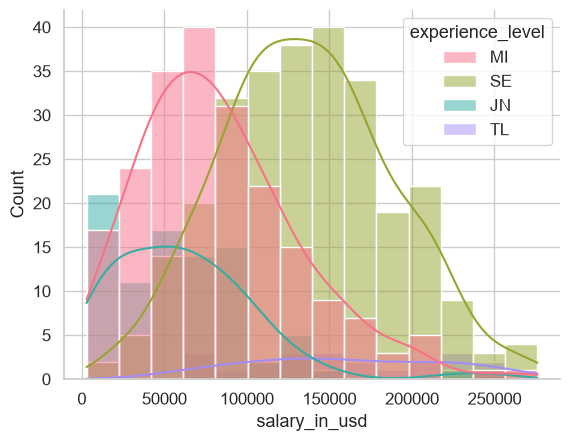

In [62]:
sns.histplot(data=data, x="salary_in_usd", hue="experience_level", kde=True);
plt.savefig('images/salary_chart3.png', dpi=300, bbox_inches='tight')
plt.show()

In [63]:
spearmanr(data.salary_in_usd, data.company_size)

SignificanceResult(statistic=np.float64(-0.10308939513387676), pvalue=np.float64(0.011726080444722028))

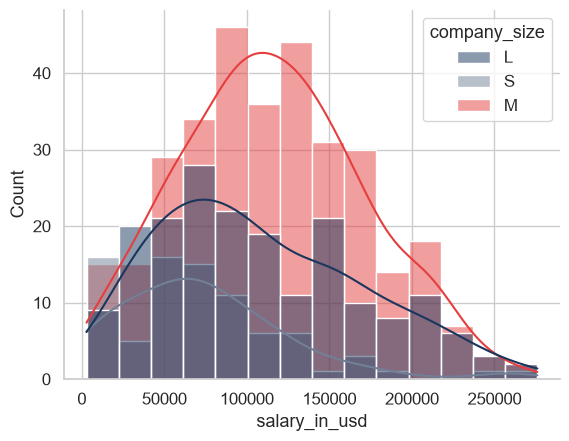

In [64]:
sns.histplot(data=data, x="salary_in_usd", hue="company_size", kde=True);
plt.savefig('images/salary_chart4.png', dpi=300, bbox_inches='tight')
plt.show()

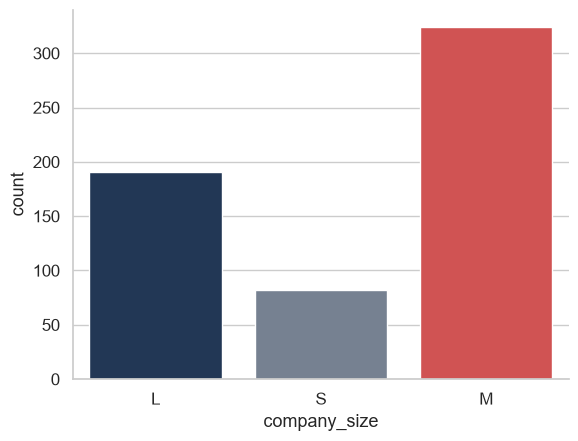

In [70]:
sns.countplot(data=data, x="company_size", hue="company_size", legend=False);
plt.savefig('images/salary_chart5.png', dpi=300, bbox_inches='tight')
plt.show()

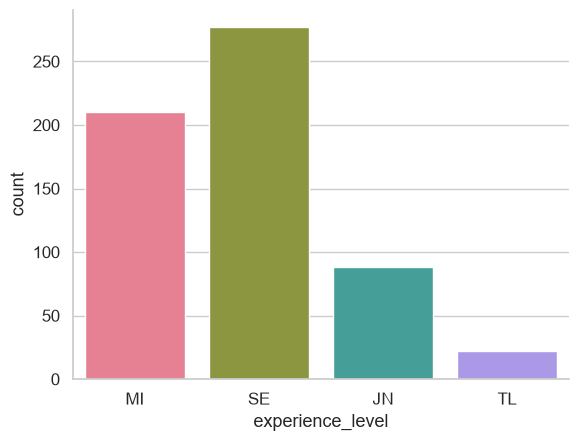

In [71]:
sns.countplot(data=data, x="experience_level", hue="experience_level", legend=False);
plt.savefig('images/salary_chart6.png', dpi=300, bbox_inches='tight')
plt.show()